# Gradient Boosting
## Regression

In this Jupyter Notebook, we will go over the typical programming progress of regression in Gradient Boosting.

We are using the Scikit-learn dataset for breast cancer.

### Step 1: Preparations

Prepare numPy for future calculations and for scikit-learn to return the breast cancer data to variables, X and y.

In [348]:
import numpy as np
from sklearn.datasets import load_breast_cancer
X, y = load_breast_cancer(return_X_y=True)
display(X)
display(y)

array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]], shape=(569, 30))

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,

### Step 2: Assigning our hyper parameters and the train test split

To begin assigning our train test split, we first import the GradientBoostingClassifier, RandomizedSearchCV (for Cross Validation), train_test_split, and log_loss and accuracy_score elements to our program.

We then create a dict of our hyper parameters:

#### n_estimators:
The number of decision trees used

#### max_depth:
The maximum number of levels for each decision tree

#### learning_rate:
The amount of improvement the next tree increments with

#### random_state:
Normally, GradientBoostingClassifier automatically creates random numbers to compare itself with. Using a fixed random state assures that we can tune our model properly to a given state, and then release it later to see how accurate the model is for other states.

In [349]:
import time
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_validate
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import log_loss
from sklearn.metrics import accuracy_score

# The base hyperparameters for our gradient boosting regression.
# By default, our loss = log loss.
# This means that the loss function we use in place in the Gradient Boosting algorithm
# is the cross entropy function.
params = dict(n_estimators=1000, max_depth=1, learning_rate=0.1, max_features = 5)

X_train, X_val, y_train, y_val = train_test_split(X, y, 
                                                    test_size = 0.2, 
                                                    random_state = 42)



### Step 3: Preventative Overfitting Measures: Cross Validation

This is the process for Cross Validation.

We create a list of parameters for RandomizedSearchCV to dissect and put a Gradient Boosting Classifier model into it.

RandomizedSearchCV also has hyper parameters of its own. In this case:
estimator is our Gradient Boosting Classifier model
param_distributions our parameters for our Gradient Boosting Classifier
n_iter is 10
our cross folds (cv) are 5
scoring is neg_root_mean_squared_error to use our metric, Root Mean Squared Error, to see our model's final loss.
and n_jobs=-1 to use all processors to run this part of the program.

We then save the best parameters and best model from our RandomizedSearchCV variable

In [350]:
param_dist = {
    'learning_rate': np.arange(0.1, 0.2, 0.01), 
    'n_estimators': [100, 200, 300, 400],  
    'max_depth': [3, 5, 7, 9],  
}

gb_model = GradientBoostingClassifier()

random_search = RandomizedSearchCV(estimator=gb_model, param_distributions=param_dist, n_iter=10, cv=5, scoring='neg_log_loss', n_jobs=-1)

random_search.fit(X_train, y_train)

best_params = random_search.best_params_
best_model = random_search.best_estimator_

y_pred_best = best_model.predict(X_val)

accuracy_best = accuracy_score(y_val, y_pred_best)

print("Best Parameters:", best_params)
print(f"Best Model Accuracy: {accuracy_best}")


Best Parameters: {'n_estimators': 100, 'max_depth': 3, 'learning_rate': np.float64(0.1)}
Best Model Accuracy: 0.956140350877193


### Step 3.5: Preventative Overfitting Measures: Early Stopping

Here is where we begin performing Early Stopping. In a way, early stopping finds a stopping point for us and gives us what is potentially the best model accuracy we can get by stopping the amount of decision trees used before our error gets out of hand with more decision trees.

To prepare, we use the same parameters as last time and add validation_fraction and n_iter_no_change to 10. The greater these numbers are, the farther they go into following decision trees after error grows back before they stop.

In [375]:
gbm_full = GradientBoostingClassifier(**params)
gbm_early_stopping = GradientBoostingClassifier(
    **params,

    # ! These are our early stopping parameters ! #
    validation_fraction=0.1,
    n_iter_no_change=7,
)

gbm_full.fit(X_train, y_train)

pred_y = gbm_full.predict(X_val)

acc = accuracy_score(y_val, pred_y)
print("Gradient Boosting Classifier accuracy is : {:.5f}".format(acc))

start_time = time.time()
gbm_full.fit(X_train, y_train)
pred_y_full = gbm_full.predict(X_val)
training_time_full = time.time() - start_time
n_estimators_full = gbm_full.n_estimators_

start_time = time.time()
gbm_early_stopping.fit(X_train, y_train)
pred_y_early_stopping = gbm_early_stopping.predict(X_val)
training_time_early_stopping = time.time() - start_time
estimators_early_stopping = gbm_early_stopping.n_estimators_

Gradient Boosting Classifier accuracy is : 0.96491


#### Simply tracking our error values as each decision tree is calculated

In [376]:
train_errors_without = []
val_errors_without = []

train_errors_with = []
val_errors_with = []

for i, (train_pred, val_pred) in enumerate(
    zip(
        gbm_full.staged_predict(X_train),
        gbm_full.staged_predict(X_val),
    )
):
    train_errors_without.append(log_loss(y_train, train_pred))
    val_errors_without.append(log_loss(y_val, val_pred))

for i, (train_pred, val_pred) in enumerate(
    zip(
        gbm_early_stopping.staged_predict(X_train),
        gbm_early_stopping.staged_predict(X_val),
    )
):
    train_errors_with.append(log_loss(y_train, train_pred))
    val_errors_with.append(log_loss(y_val, val_pred))

### Graphing our results:

Here, we can see that without early stopping, the number of trees made continues until our parameters say so, and the error dips and continues to rise again after its lowest point.

With early stopping, we can see the our error continues all the way and ends suddenly around its lowest point. Thus, early stopping does finds the best model possible under its validation_fraction and n_iter_no_change conditions.

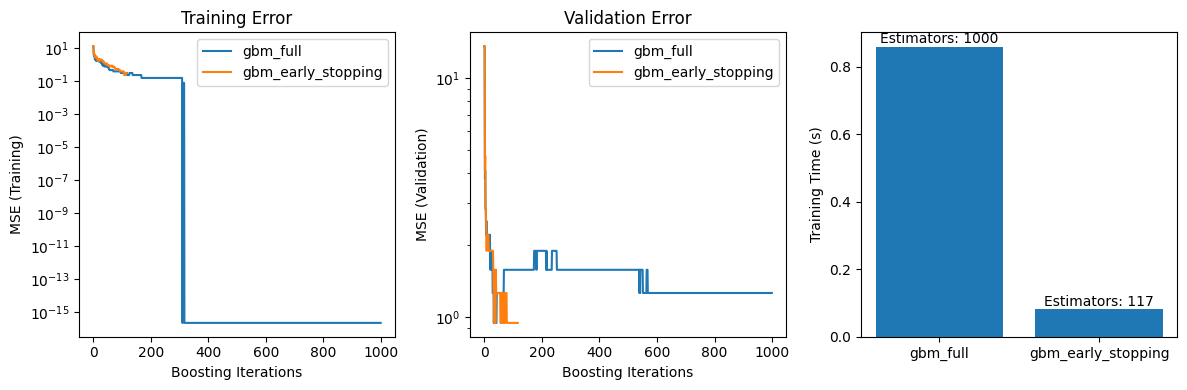

In [377]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 4))

axes[0].plot(train_errors_without, label="gbm_full")
axes[0].plot(train_errors_with, label="gbm_early_stopping")
axes[0].set_xlabel("Boosting Iterations")
axes[0].set_ylabel("MSE (Training)")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].set_title("Training Error")

axes[1].plot(val_errors_without, label="gbm_full")
axes[1].plot(val_errors_with, label="gbm_early_stopping")
axes[1].set_xlabel("Boosting Iterations")
axes[1].set_ylabel("MSE (Validation)")
axes[1].set_yscale("log")
axes[1].legend()
axes[1].set_title("Validation Error")

training_times = [training_time_full, training_time_early_stopping]
labels = ["gbm_full", "gbm_early_stopping"]
bars = axes[2].bar(labels, training_times)
axes[2].set_ylabel("Training Time (s)")

for bar, n_estimators in zip(bars, [n_estimators_full, estimators_early_stopping]):
    height = bar.get_height()
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.001,
        f"Estimators: {n_estimators}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

### Results

Here we calculate the accuracy score as our metric to see how well our final models did.

In [378]:
test_rmse_full = accuracy_score(y_val, pred_y_full) ** (1 / 2)
test_rmse_early_stopping = accuracy_score(y_val, pred_y_early_stopping) ** (1 / 2)

print('Accuracy score (full): {:.5f}'.format(test_rmse_full))
print('Accuracy score (early stopping): {:.5f}'.format(test_rmse_early_stopping))

Accuracy score (full): 0.98230
Accuracy score (early stopping): 0.98675


Looking at the graph, we can see that the number of estimators and accuracy score for early stopping ended at is similar to the number of estimators and accuracy score for cross validation came to. However, early stopping, in this case, is quite better than cross validation: 

Cross Validation:
Best Parameters: {'n_estimators': 100, 'max_depth': 3, 'learning_rate': np.float64(0.17999999999999997)}

Best Model Accuracy: 0.956140350877193

Early Stopping:

n_estimators = 56

Accuracy Score (early stopping): 0.98675